# LCEL, Output Parsers, Groq API, and LangSmith Tracing

This notebook covers:

- LCEL and the pipe operator (`|`)
- Output parsers (`StrOutputParser`, `JsonOutputParser`, `PydanticOutputParser`)
- A real Groq API example with LangChain
- Automatic tracing with LangSmith
- Selective tracing with `tracing_context`
- A practical pattern for prompt → model → parser chains

Official references:
- Structured output
- Tracing quickstart
- Trace LangChain applications
- Groq integration

## Learning goals

By the end of this notebook, you should be able to:

1. Build an LCEL chain with `prompt | model | parser`
2. Use Groq as the chat model backend
3. Parse plain text, JSON, and Pydantic-typed output
4. Turn on LangSmith tracing with environment variables
5. Trace a specific call with `tracing_context`

## 1) Install the required packages

Run this in a notebook cell or your terminal:

```bash
pip install -U langchain langchain-groq langsmith python-dotenv pydantic
```

The Groq integration lives in `langchain-groq`, and LangSmith is used for tracing and observability.

In [1]:
%pip install -qU langchain langchain-groq langsmith python-dotenv pydantic

Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-aws 1.1.0 requires numpy<3,>=2.3.2; python_version >= "3.12", but you have numpy 1.26.4 which is incompatible.
langchain-community 0.4.1 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
langchain-tests 1.1.4 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
langchain-tests 1.1.4 requires pytest<9.0.0,>=7.0.0, but you have pytest 9.0.3 which is incompatible.
sagemaker 2.245.0 requires packaging<25,>=23.0, but you have packaging 26.0 which is incompatible.
sagemaker-mlops 1.5.0 requires sagemaker-core>=2.5.0, but you have sagemaker-core 1.0.77 which is incompatible.
sagemaker-serve 1.5.0 requires sagemaker-core>=2.5.0, but you have sagema

## 2) Configure environment variables

Create a `.env` file with your keys.

```env
GROQ_API_KEY=your_groq_api_key
LANGSMITH_API_KEY=your_langsmith_api_key
LANGSMITH_TRACING=true
LANGSMITH_PROJECT=lcel-groq-demo
```

LangSmith's tracing quickstart recommends enabling tracing with `LANGSMITH_TRACING=true` and setting your API key.

In [2]:
from dotenv import load_dotenv
import os

load_dotenv()

# You may also set values interactively if they are missing.
# Uncomment if needed:
# import getpass
# if not os.getenv("GROQ_API_KEY"):
#     os.environ["GROQ_API_KEY"] = getpass.getpass("Enter GROQ_API_KEY: ")
# if not os.getenv("LANGSMITH_API_KEY"):
#     os.environ["LANGSMITH_API_KEY"] = getpass.getpass("Enter LANGSMITH_API_KEY: ")

print("GROQ_API_KEY loaded:", bool(os.getenv("GROQ_API_KEY")))
print("LANGSMITH_API_KEY loaded:", bool(os.getenv("LANGSMITH_API_KEY")))
print("LANGSMITH_TRACING:", os.getenv("LANGSMITH_TRACING"))
print("LANGSMITH_PROJECT:", os.getenv("LANGSMITH_PROJECT"))

GROQ_API_KEY loaded: True
LANGSMITH_API_KEY loaded: True
LANGSMITH_TRACING: true
LANGSMITH_PROJECT: lcel-groq-demo


## 3) What LCEL is

LCEL stands for LangChain Expression Language.

The key idea is simple: build chains by piping components together.

```python
chain = prompt | model | output_parser
```

The output of one step becomes the input to the next step.

## 4) Imports

We will use:

- `ChatGroq` for the Groq model
- `ChatPromptTemplate` for reusable prompt composition
- `StrOutputParser` for plain text extraction
- `JsonOutputParser` and `PydanticOutputParser` for structured data
- `tracing_context` for selective tracing

In [3]:
from pydantic import BaseModel, Field

from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_core.output_parsers import StrOutputParser, JsonOutputParser, PydanticOutputParser

# LangSmith tracing utilities
from langsmith import tracing_context

## 5) Create the Groq chat model

LangChain's Groq integration uses the `langchain-groq` package, and the official integration page shows `ChatGroq` as the Python class for Groq-hosted models. The integration supports features such as token-level streaming, structured output, and token usage. 

In [4]:
llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0,
    max_retries=2,
)

print(llm)

output_version=None profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True} client=<groq.resources.chat.completions.Completions object at 0x0000024DDABB6BA0> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000024DDABB78C0> model_name='llama-3.3-70b-versatile' temperature=1e-08 model_kwargs={} groq_api_key=SecretStr('**********') groq_api_base=None groq_proxy=None


## 6) A basic LCEL chain: prompt → model → string output

This is the simplest and most common LCEL pattern.

We will:
1. Build a chat prompt
2. Send it to Groq
3. Extract plain text with `StrOutputParser`

In [5]:
prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful assistant that answers clearly and concisely."),
    ("user", "Explain {topic} in 3 bullet points."),
])

chain = prompt | llm | StrOutputParser()

result = chain.invoke({"topic": "LCEL"})
print(result)

LCEL (Lowest Common Emulating Layer) is not a widely recognized term, but I can provide information on a similar concept, LCE (Lowest Common Environment) or LCEL (Lowest Common Emulation Layer) which might be related to what you're asking. Here are three bullet points:

* LCEL is a concept that refers to the lowest-level environment or layer that can emulate or support multiple higher-level systems, applications, or protocols.
* The goal of LCEL is to provide a common foundation that allows different systems or applications to interact and communicate with each other seamlessly, despite their differences.
* By establishing a LCEL, developers can create a standardized interface or platform that enables interoperability, simplifies development, and reduces the complexity of integrating multiple systems or applications.


## 7) Why `StrOutputParser` is useful

`StrOutputParser` converts model outputs into a plain string so the next step in your application can work with simple text instead of message objects. The LangChain reference describes it as a parser that extracts text content from model outputs. citeturn433074search1

In [6]:
# Another example with a different topic
print(chain.invoke({"topic": "output parsers"}))

Here are 3 key points about output parsers:
* An output parser is a software component that analyzes and interprets the output of a system, application, or command, extracting relevant information from it.
* Output parsers typically use predefined rules, patterns, or formats to identify and extract specific data, such as error messages, log entries, or performance metrics.
* The extracted data is then often used for further processing, reporting, or decision-making, such as alerting, monitoring, or automating tasks, to help improve system efficiency, reliability, or user experience.


## 8) Structured output with `JsonOutputParser`

When you need machine-readable output, ask the model to return JSON and parse it.

The LangChain reference describes `JsonOutputParser` as a parser for JSON objects and notes that it is a strong choice when you want structured data without function calling. citeturn308083search1turn308083search2

In [7]:
json_parser = JsonOutputParser()

json_prompt = PromptTemplate.from_template(
    '''Return a JSON object with keys:
- concept
- summary
- use_case

Format instructions:
{format_instructions}

Topic: {topic}'''
).partial(format_instructions=json_parser.get_format_instructions())

json_chain = json_prompt | llm | json_parser

json_result = json_chain.invoke({"topic": "LCEL"})
print(json_result)
print(type(json_result))

{'concept': "LCEL stands for Large Cell Epithelioid Lymphoma, but it's not clear if that's the context. However, another term LCEL could refer to is Localized Cutaneous Epithelioid Lymphoma or more commonly, Lymphocytic Epithelioid Cell lymphoma, or it could be related to Large Cell Epithelioid Lymphoma in a different context. Without more context, it's hard to pinpoint the exact concept of LCEL. However, in a general medical context, LCEL could be referring to a rare type of non-Hodgkin lymphoma.", 'summary': 'LCEL, in a general sense, seems to refer to a medical condition involving lymphoma, which is a type of cancer that begins in cells of the lymph system. The lymph system is part of the immune system, helping to fight infection and disease. Lymphoma can occur in many parts of the body, including the lymph nodes, spleen, bone marrow, and other organs. The specific type of LCEL would determine the exact nature of the condition, its symptoms, diagnosis, and treatment options.', 'use_

## 9) Structured output with `PydanticOutputParser`

A Pydantic parser gives you validated Python objects.

The LangChain reference describes `PydanticOutputParser` as parsing the output of an LLM call into a Pydantic object. citeturn308083search0

In [8]:
class LcelSummary(BaseModel):
    concept: str = Field(..., description="The concept being explained")
    summary: str = Field(..., description="A short explanation")
    example: str = Field(..., description="A practical example")


pyd_parser = PydanticOutputParser(pydantic_object=LcelSummary)

pyd_prompt = PromptTemplate.from_template(
    '''You are a technical instructor.

Return the answer in the exact format below.

{format_instructions}

Topic: {topic}'''
).partial(format_instructions=pyd_parser.get_format_instructions())

pyd_chain = pyd_prompt | llm | pyd_parser

typed_result = pyd_chain.invoke({"topic": "LCEL piping"})
print(typed_result)
print(type(typed_result))

concept='LCEL piping' summary='LCEL piping, or Low Temperature Carbon Steel piping, refers to a type of piping system designed to operate at extremely low temperatures, typically below -20°C. It is commonly used in cryogenic applications such as liquefied natural gas (LNG) processing and storage.' example='An example of LCEL piping can be seen in the transportation of liquefied natural gas (LNG) via pipelines, where the piping system is designed to withstand the extremely low temperatures of the LNG, ensuring safe and efficient transportation of the fuel.'
<class '__main__.LcelSummary'>


## 10) Tracing in LangSmith

LangSmith gives end-to-end visibility into your LangChain and LangGraph applications.

The official tracing docs show that you can enable tracing with environment variables and then run your LangChain code normally; each step is captured as a trace and individual runs. The quickstart also says no extra code is needed to log a trace once the environment is set up. 

### Automatic tracing setup

These environment variables are the important ones:

```env
LANGSMITH_TRACING=true
LANGSMITH_API_KEY=...
LANGSMITH_PROJECT=lcel-groq-demo
```

If your workspace uses a non-default LangSmith region, the docs also explain that you may need to set `LANGSMITH_ENDPOINT`. citeturn830326search11turn691423search1

In [9]:
# Running the chain now should create traces in LangSmith
# as long as LANGSMITH_TRACING=true and LANGSMITH_API_KEY is set.

auto_traced_result = chain.invoke({"topic": "prompt templates"})
print(auto_traced_result)

Here are 3 bullet points explaining prompt templates:
* **Definition**: Prompt templates are pre-designed structures or formats used to guide the creation of prompts or questions, helping to ensure clarity and consistency in the input or query.
* **Purpose**: The purpose of prompt templates is to facilitate effective communication, reduce ambiguity, and increase the likelihood of receiving relevant and accurate responses or results.
* **Benefits**: Using prompt templates can save time, improve productivity, and enhance the overall quality of interactions, whether it's in a conversational AI, survey, or other applications where clear and concise input is essential.


## 11) Selective tracing with `tracing_context`

Sometimes you want to trace only specific calls.

LangSmith documents `tracing_context` for selectively enabling or disabling tracing within a block, and it can also override the project name and tags for the runs inside that block. 

In [10]:
with tracing_context(enabled=True, project_name=os.getenv("LANGSMITH_PROJECT", "lcel-groq-demo"), tags=["demo", "groq", "lcel"]):
    traced_result = chain.invoke({"topic": "LangSmith tracing"})

print(traced_result)

LangSmith tracing is a method used to help individuals with speech or language difficulties. Here are three key points about LangSmith tracing:
* LangSmith tracing involves using a finger or stylus to trace the shape of words or letters on a surface, helping to develop motor skills and hand-eye coordination.
* This method can aid in improving spelling, reading, and writing abilities by reinforcing the connection between visual and kinesthetic learning.
* By practicing LangSmith tracing, individuals can develop muscle memory and increase their ability to recognize and reproduce written words, ultimately enhancing their overall language skills.


In [11]:
# Example: temporarily disable tracing for a sensitive or noisy request
with tracing_context(enabled=False):
    untraced_result = chain.invoke({"topic": "selective tracing"})

print(untraced_result)

Selective tracing is a debugging technique used to identify and diagnose issues in complex systems. Here are three key points about selective tracing:

* **Targeted logging**: Selective tracing involves logging specific events or transactions in a system, allowing developers to focus on the most relevant information and filter out unnecessary data.
* **Conditional tracing**: This technique enables tracing to be turned on or off based on certain conditions, such as error codes, user IDs, or specific system states, to minimize overhead and maximize relevance.
* **Real-time insight**: By applying selective tracing, developers can gain real-time insight into system behavior, identify performance bottlenecks, and troubleshoot issues more efficiently, ultimately leading to faster resolution and improved system reliability.


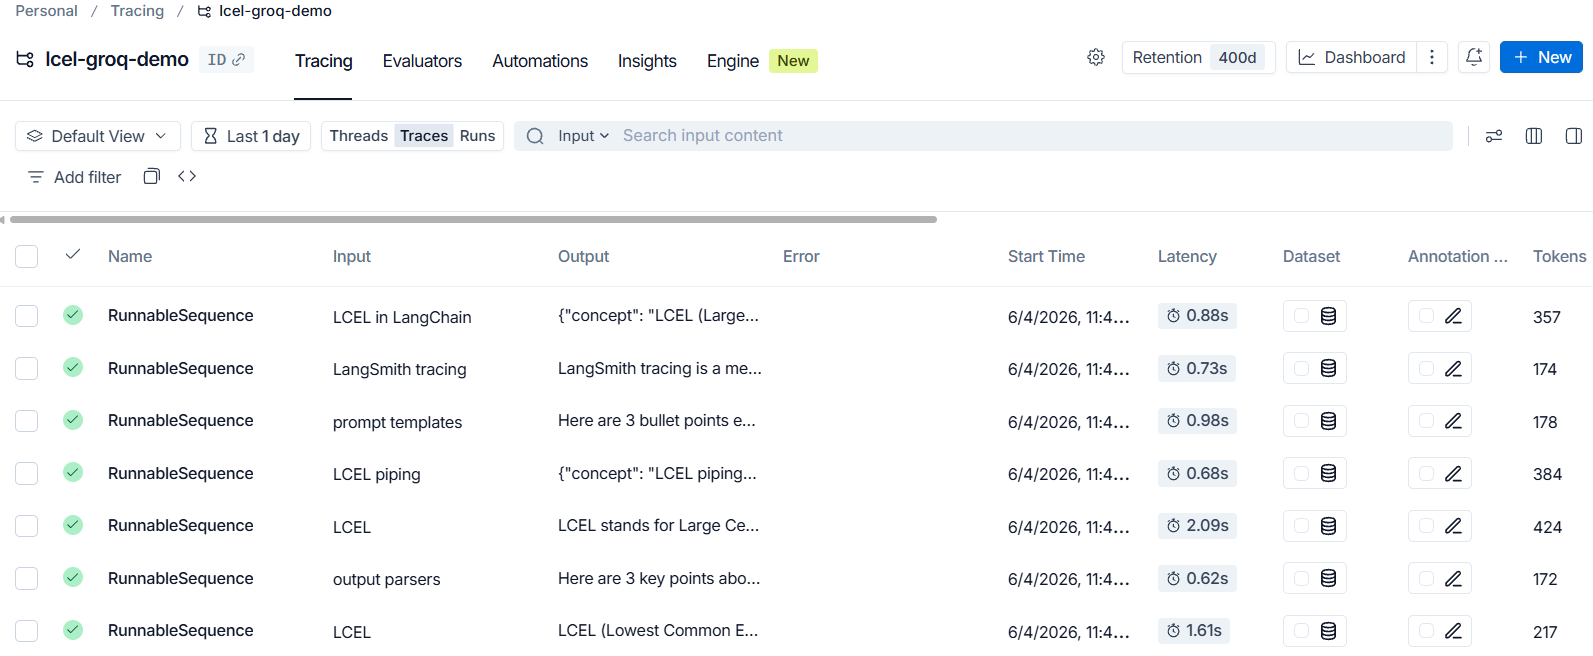

## 12) A practical prompt → model → parser workflow

A production-friendly LCEL chain often follows this pattern:

1. Validate input
2. Build a prompt
3. Call the model
4. Parse the output
5. Log traces and metrics
6. Handle parser failures with a fallback

This is where LCEL and LangSmith fit together nicely: LCEL gives you a clean composition style, and LangSmith gives you the trace data to debug and improve the chain. citeturn177667search3turn830326search4

In [12]:
def safe_chain_invoke(topic: str):
    try:
        return pyd_chain.invoke({"topic": topic})
    except Exception as e:
        return {"error": str(e), "topic": topic}

safe_chain_invoke("LCEL in LangChain")

LcelSummary(concept='LCEL (Large Complex Embeddings) in LangChain', summary='LCEL is a technique used in LangChain to efficiently store and manage large complex embeddings, enabling more effective and scalable language modeling', example='For instance, in a conversational AI application, LCEL can be used to store user preferences and conversation history, allowing the model to provide more personalized and context-aware responses')

## 13) When to use which parser

- Use `StrOutputParser` when you only need a clean text string.
- Use `JsonOutputParser` when you want a dictionary-like JSON response.
- Use `PydanticOutputParser` when you want validated typed objects in Python.

For more reliable structured responses in agent workflows, LangChain also provides structured output patterns in the core docs. 

## 14) Common failure mode

If the model does not follow the required format, parsing can fail.

The LangChain docs note that output parsing errors often improve when you make the formatting instructions more precise or use more capable models. 

## Key takeaways

- LCEL chains are built by piping components together with `|`.
- `prompt | model | parser` is the core pattern.
- Groq integrates cleanly through `ChatGroq`.
- `StrOutputParser` is for plain text.
- `JsonOutputParser` and `PydanticOutputParser` are for structured output.
- LangSmith tracing is enabled with environment variables and can be scoped with `tracing_context`.

## References

- Structured output: https://docs.langchain.com/oss/python/langchain/structured-output
- Tracing quickstart: https://docs.langchain.com/langsmith/observability-quickstart
- Trace LangChain applications: https://docs.langchain.com/langsmith/trace-with-langchain
- LangSmith observability: https://docs.langchain.com/langsmith/observability
- Groq integration: https://docs.langchain.com/oss/python/integrations/chat/groq